## Walking forward

A holdout is one look at one stretch. `probatum.validate` trades several stretches out of
sample instead, each with the parameters a search chose on bars that hold none of it, and
joins them into one run, a path. Here the crossing of two averages on hourly Bitcoin bars of
2024 and 2025: a rolling walk-forward, trained on the 120 days before each month it trades,
then an anchored one, trained on every bar before.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 3.0.0, exchange-router 3.3.0


### The bars

In [2]:
PATH = pathlib.Path("../bars/binance-spot-btcusdt-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    data.save(path=PATH)

data

Data(BTCUSDT, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00)

### A rolling walk-forward

Each window trades the next 30 days with the winner of a search of 40 random trials on the
120 days before them. The account is carried across each seam, where the orders not yet
filled are cancelled. The last 20% of the bars stay held out.

In [3]:
def crossing(data, fast, slow):
    up   = probatum.ta.ema(data.close, length=fast)
    down = probatum.ta.ema(data.close, length=slow)
    return numpy.where(up > down, 1.0, 0.0)


space = {"fast": probatum.Int(low=6, high=72),
         "slow": probatum.Int(low=96, high=528)}

rolling = probatum.validate(crossing, data=data, venue="binance_spot",
                            cv=probatum.cv.WalkForward(train=24 * 120, test=24 * 30),
                            space=space, search={"trials": 40, "sampler": "random"},
                            holdout=0.2, seed=7)

rolling

,value,low,high,level,method,why_none
paths,1,,,,,
score,0.63,-1.11,2.36,0.95,"delta method, Newey-West lag 8, floored at lag zero",
windows,15,,,,,
windows_gained,9,,,,,
decay,2.15,,,,,
decay_error,1.23,,,,,
costs,969,,,,,
price_pnl,"3,108",,,,,
holdout,,,,,,1
buy_and_hold,,,,,,1


### Its windows

Each stretch a fit traded: the rows it owns, the parameters its search chose, and what it
scored there.

In [4]:
windows = rolling.windows.to_pandas()
fits    = rolling.fits.to_pandas()

windows = windows.merge(fits[["number", "fast", "slow", "fitted"]], left_on="fit",
                        right_on="number")

windows[["fit", "first_time", "last_time", "fast", "slow", "fitted", "score",
         "total_return_pct"]].round(decimals=2)

,fit,first_time,last_time,fast,slow,fitted,score,total_return_pct
0,0,2024-04-30 01:00:00+00:00,2024-05-30 00:00:00+00:00,16,299,3.17,-0.78,-2.73
1,1,2024-05-30 01:00:00+00:00,2024-06-29 00:00:00+00:00,43,113,3.64,0.44,0.44
2,2,2024-06-29 01:00:00+00:00,2024-07-29 00:00:00+00:00,71,104,0.21,0.96,2.26
3,3,2024-07-29 01:00:00+00:00,2024-08-28 00:00:00+00:00,23,483,1.92,-6.33,-12.90
4,4,2024-08-28 01:00:00+00:00,2024-09-27 00:00:00+00:00,53,369,1.42,4.90,12.05
5,5,2024-09-27 01:00:00+00:00,2024-10-27 00:00:00+00:00,49,376,2.02,-0.56,-2.04
6,6,2024-10-27 01:00:00+00:00,2024-11-26 00:00:00+00:00,14,118,1.94,8.04,38.19
7,7,2024-11-26 01:00:00+00:00,2024-12-26 00:00:00+00:00,12,98,3.85,0.54,1.10
8,8,2024-12-26 01:00:00+00:00,2025-01-25 00:00:00+00:00,25,491,3.46,0.84,2.30
9,9,2025-01-25 01:00:00+00:00,2025-02-24 00:00:00+00:00,24,417,3.43,-6.40,-9.90


### Decay and consistency

The decay is the mean gap between what a fit scored on its training bars and what its
window then earned, a positive one worse out of sample; the consistency counts the windows
past the objective's break-even.

In [5]:
print(rolling.decay())

rolling.consistency()

                           first                      last    fitted  \
window                                                                 
0      2024-04-30 01:00:00+00:00 2024-05-30 00:00:00+00:00  3.170961   
1      2024-05-30 01:00:00+00:00 2024-06-29 00:00:00+00:00  3.643602   
2      2024-06-29 01:00:00+00:00 2024-07-29 00:00:00+00:00  0.210873   
3      2024-07-29 01:00:00+00:00 2024-08-28 00:00:00+00:00  1.918623   
4      2024-08-28 01:00:00+00:00 2024-09-27 00:00:00+00:00  1.415466   
5      2024-09-27 01:00:00+00:00 2024-10-27 00:00:00+00:00  2.017421   
6      2024-10-27 01:00:00+00:00 2024-11-26 00:00:00+00:00  1.938991   
7      2024-11-26 01:00:00+00:00 2024-12-26 00:00:00+00:00  3.851002   
8      2024-12-26 01:00:00+00:00 2025-01-25 00:00:00+00:00  3.464979   
9      2025-01-25 01:00:00+00:00 2025-02-24 00:00:00+00:00  3.425562   
10     2025-02-24 01:00:00+00:00 2025-03-26 00:00:00+00:00  2.060931   
11     2025-03-26 01:00:00+00:00 2025-04-25 00:00:00+00:00 -0.58

,scores
0,-0.782614
1,0.435853
2,0.958119
3,-6.332939
4,4.898447
5,-0.560226
6,8.035971
7,0.543727
8,0.844206
9,-6.401294


### The path, window by window

The path's equity from its returns, each window shaded in turn and named by the lengths it
traded.

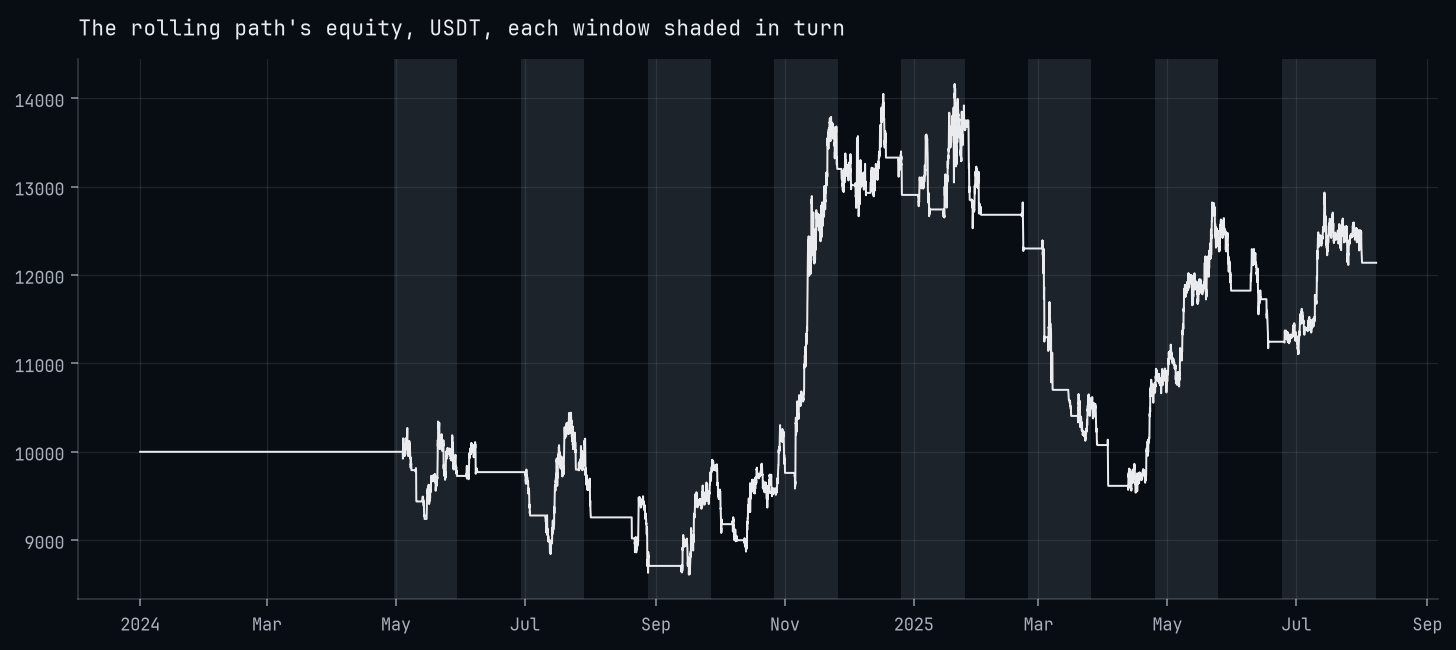

In [6]:
times  = pandas.to_datetime(data.time[:rolling.returns.shape[1]], utc=True)
equity = 10_000.0 * numpy.cumprod(1.0 + numpy.nan_to_num(rolling.returns[0]))

figure, axes = matplotlib.pyplot.subplots(figsize=(10.0, 4.4))
for k, window in windows.iterrows():
    if k % 2 == 0:
        axes.axvspan(xmin=times[window["first"]], xmax=times[window["last"]], color="C3",
                     alpha=0.25, linewidth=0.0)
axes.plot(times, equity, linewidth=1.0)
axes.set_title(label="The rolling path's equity, USDT, each window shaded in turn")
matplotlib.pyplot.show()

### Anchored

The same, each window trained on every bar before it.

In [7]:
anchored = probatum.validate(crossing, data=data, venue="binance_spot",
                             cv=probatum.cv.WalkForward(train=24 * 120, test=24 * 30,
                                                        anchored=True),
                             space=space, search={"trials": 40, "sampler": "random"},
                             holdout=0.2, seed=7)

anchored.summary()

,value,low,high,level,method,why_none
paths,1,,,,,
score,1.04,-0.70,2.77,0.95,"delta method, Newey-West lag 9, floored at lag zero",
windows,15,,,,,
windows_gained,9,,,,,
decay,1.84,,,,,
decay_error,1.08,,,,,
costs,859,,,,,
price_pnl,"5,118",,,,,
holdout,,,,,,1
buy_and_hold,,,,,,1


### Both paths

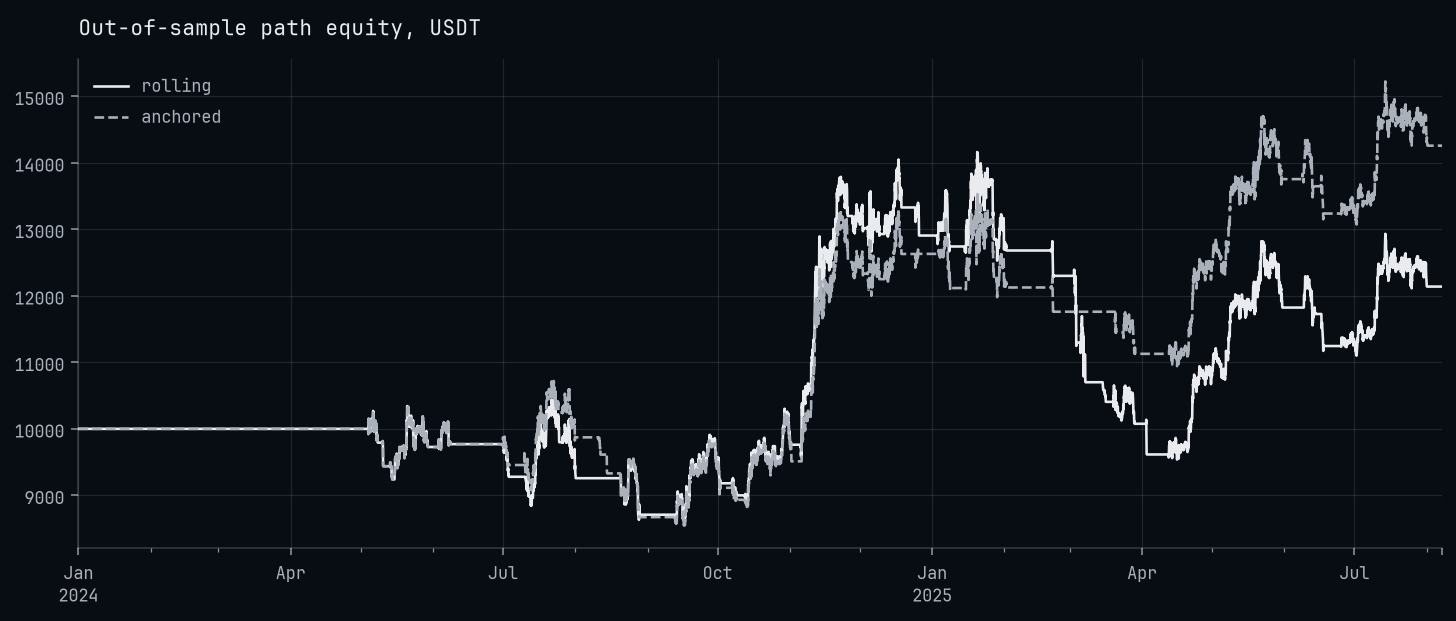

In [8]:
both = pandas.DataFrame(index=times)
for name, study in {"rolling": rolling, "anchored": anchored}.items():
    both[name] = 10_000.0 * numpy.cumprod(1.0 + numpy.nan_to_num(study.returns[0]))

axes = both.plot(title="Out-of-sample path equity, USDT", xlabel="")
matplotlib.pyplot.show()